# Proyecto 2: GAN de Personajes 
## Jonathan Zacarias 231104 



In [1]:
%pip uninstall -y torch torchvision torchaudio
%pip install torch torchvision

Found existing installation: torch 2.14.1
Uninstalling torch-2.14.1:
  Successfully uninstalled torch-2.14.1
Found existing installation: torchvision 0.29.1
Uninstalling torchvision-0.29.1:
  Successfully uninstalled torchvision-0.29.1
Note: you may need to restart the kernel to use updated packages.


  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp312-cp312-win_amd64.whl.metadata (5.7 kB)
Using cached torch-2.14.1-cp312-cp312-win_amd64.whl (124.1 MB)
Using cached torchvision-0.29.1-cp312-cp312-win_amd64.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch, torchvision
print(torch.__version__, torchvision.__version__, torch.cuda.is_available())

2.14.1+cpu 0.29.1+cpu False


In [3]:
import torch, torch.optim as optim
print(torch.__file__)
print(optim.Adam)

c:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\__init__.py
<class 'torch.optim.adam.Adam'>


In [1]:
# 1. Configuración, Semillas y Parámetros
import os
import random
import glob
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, utils, models
from torch.nn.utils import spectral_norm

# Semilla reproducible global
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo en uso: {device}')

# Hiperparámetros base
LATENT_DIM = 100
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999
EPOCHS = 60

# Directorios requeridos
for folder in ['data_raw', 'data64', 'galeria', 'checkpoints', 'output_eval']:
    os.makedirs(folder, exist_ok=True)


Dispositivo en uso: cpu


In [5]:
# 2. Preprocesamiento de Sprites (data64/)
def process_pixel_art_image(image_path, output_path, target_size=64, bg_color=(255, 255, 255)):
    with Image.open(image_path) as img:
        img = img.convert('RGBA')
        background = Image.new('RGBA', img.size, bg_color + (255,))
        img_composited = Image.alpha_composite(background, img).convert('RGB')
        
        w, h = img_composited.size
        max_dim = max(w, h)
        square_img = Image.new('RGB', (max_dim, max_dim), bg_color)
        paste_x = (max_dim - w) // 2
        paste_y = (max_dim - h) // 2
        square_img.paste(img_composited, (paste_x, paste_y))
        
        # Resampling NEAREST para no difuminar el pixel art
        final_img = square_img.resize((target_size, target_size), Image.Resampling.NEAREST)
        final_img.save(output_path, 'PNG')

def prepare_dataset(raw_dir='data_raw', processed_dir='data64'):
    raw_files = glob.glob(f'{raw_dir}/**/*.*', recursive=True)
    valid_exts = {'.png', '.jpg', '.jpeg'}
    processed_count = 0
    for f in raw_files:
        ext = os.path.splitext(f)[1].lower()
        if ext in valid_exts:
            out_filename = f'sprite_{processed_count:05d}.png'
            process_pixel_art_image(f, os.path.join(processed_dir, out_filename))
            processed_count += 1
    print(f'Imágenes procesadas y guardadas en {processed_dir}: {processed_count}')

# Ejecutar preprocesamiento
prepare_dataset()


Imágenes procesadas y guardadas en data64: 312


In [2]:
import itertools, os, glob, shutil
from PIL import Image

shutil.rmtree('data64_aug', ignore_errors=True)

def augment_and_save(src_dir='data64', out_dir='data64_aug'):
    os.makedirs(out_dir, exist_ok=True)
    n = 0
    for p in sorted(glob.glob(f'{src_dir}/*.png')):
        im = Image.open(p).convert('RGB')
        for flip in (False, True):
            base = im.transpose(Image.FLIP_LEFT_RIGHT) if flip else im
            ch = base.split()
            for perm in itertools.permutations(range(3)):
                Image.merge('RGB', [ch[i] for i in perm]).save(f'{out_dir}/s_{n:06d}.png')
                n += 1
    print('Originales:', len(glob.glob(f'{src_dir}/*.png')), '| Tras aumento:', n)

augment_and_save()

Originales: 200 | Tras aumento: 2400


In [3]:
# 3. Dataset y DataLoader PyTorch
class PixelArtDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.image_paths = sorted(glob.glob(os.path.join(root_dir, '*.png')))
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = PixelArtDataset('data64_aug', transform=transform)
if len(dataset) > 0:
    train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    print(f'Total de imágenes cargadas: {len(dataset)} | Batches por época: {len(train_loader)}')
else:
    print('Aviso: Coloca imágenes en data_raw/ o data64/ para entrenar.')


Total de imágenes cargadas: 2400 | Batches por época: 37


In [4]:
# 4. Arquitectura: DCGAN Base + Discriminador con Spectral Normalization
class Generator(nn.Module):
    def __init__(self, z_dim=100, channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

class DiscriminatorSpectral(nn.Module):
    def __init__(self, channels=3, use_spectral_norm=True):
        super().__init__()
        def conv_layer(in_f, out_f, k=4, s=2, p=1, apply_bn=True):
            conv = nn.Conv2d(in_f, out_f, kernel_size=k, stride=s, padding=p, bias=not apply_bn)
            if use_spectral_norm:
                conv = spectral_norm(conv)
            layers = [conv]
            if apply_bn and not use_spectral_norm:
                layers.append(nn.BatchNorm2d(out_f))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.net = nn.Sequential(
            *conv_layer(channels, 64, apply_bn=False),
            *conv_layer(64, 128),
            *conv_layer(128, 256),
            *conv_layer(256, 512),
            spectral_norm(nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=True)) if use_spectral_norm else nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=True),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

torch.manual_seed(SEED)
netG = Generator(LATENT_DIM, CHANNELS).to(device)
netD = DiscriminatorSpectral(CHANNELS, use_spectral_norm=True).to(device)
netG.apply(weights_init)

criterion = nn.BCELoss()
_g = torch.Generator().manual_seed(123)
FIXED_NOISE_EVAL = torch.randn(16, LATENT_DIM, 1, 1, generator=_g).to(device)
torch.save(FIXED_NOISE_EVAL.cpu(), 'checkpoints/fixed_noise.pt')
optG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, BETA2))
optD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, BETA2))


Iniciando entrenamiento con Spectral Normalization...
Época [1/60] | D: 0.6367 | G: 2.6758
Época [5/60] | D: 0.5827 | G: 2.6679
Época [10/60] | D: 0.6455 | G: 2.1950
Época [15/60] | D: 0.9602 | G: 1.4736
Época [20/60] | D: 0.9778 | G: 1.4323
Época [25/60] | D: 0.9204 | G: 1.6237
Época [30/60] | D: 0.8632 | G: 1.8403
Época [35/60] | D: 0.7454 | G: 1.8538
Época [40/60] | D: 0.7105 | G: 1.9963
Época [45/60] | D: 0.7305 | G: 1.8195
Época [50/60] | D: 0.7321 | G: 1.6928
Época [55/60] | D: 0.7696 | G: 1.5896
Época [60/60] | D: 0.8134 | G: 1.5861


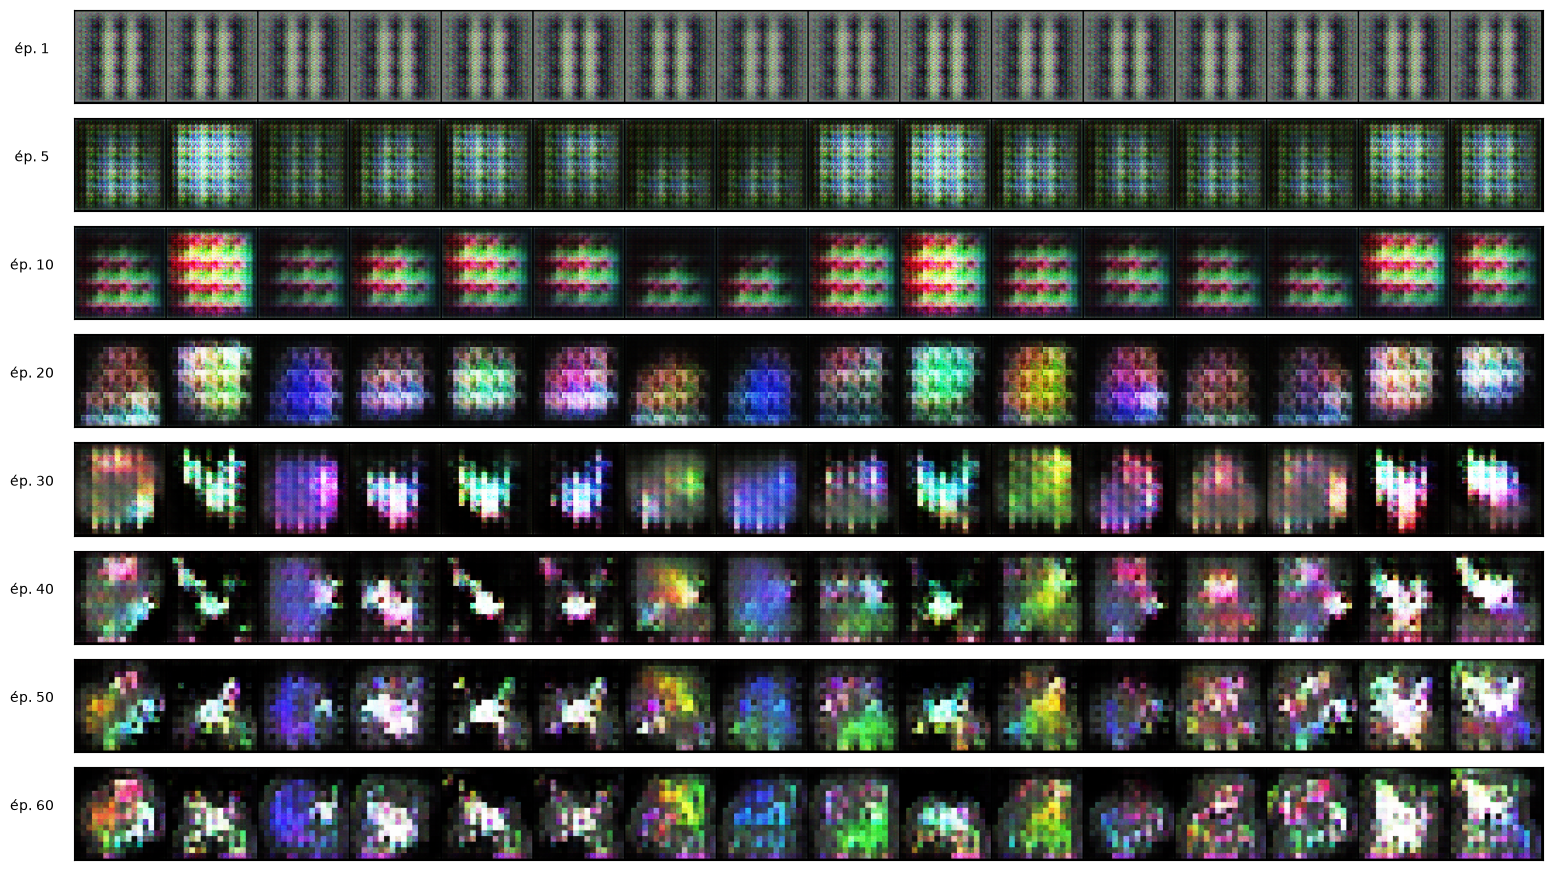

Entrenamiento concluido.


In [5]:
import copy

def recalibrate_bn(G, n_batches=100):
    # Recalcula las estadísticas de BatchNorm para que el modo eval no dé basura
    for m in G.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats(); m.momentum = None
    G.train()
    with torch.no_grad():
        for _ in range(n_batches):
            G(torch.randn(256, LATENT_DIM, 1, 1, device=device))
    G.eval()

assert len(dataset) > 0, 'Dataset vacío: revisa data64_aug'
history_loss_G, history_loss_D = [], []
snaps = {}
SNAP_EPOCHS = {1, 5, 10, 20, 30, 40, 50, 60}

print('Iniciando entrenamiento con Spectral Normalization...')
for epoch in range(1, EPOCHS + 1):
    netG.train(); netD.train()
    epoch_d_loss = epoch_g_loss = 0.0
    for real_images in train_loader:
        b_size = real_images.size(0)
        real_images = real_images.to(device)
        real_labels = torch.ones(b_size, 1, device=device)
        fake_labels = torch.zeros(b_size, 1, device=device)

        optD.zero_grad()
        loss_d_real = criterion(netD(real_images), real_labels)
        fake_images = netG(torch.randn(b_size, LATENT_DIM, 1, 1, device=device))
        loss_d_fake = criterion(netD(fake_images.detach()), fake_labels)
        loss_d = loss_d_real + loss_d_fake
        loss_d.backward(); optD.step()

        optG.zero_grad()
        loss_g = criterion(netD(fake_images), real_labels)
        loss_g.backward(); optG.step()

        epoch_d_loss += loss_d.item(); epoch_g_loss += loss_g.item()

    history_loss_D.append(epoch_d_loss / len(train_loader))
    history_loss_G.append(epoch_g_loss / len(train_loader))

    if epoch in SNAP_EPOCHS or epoch == EPOCHS:
        tmp = copy.deepcopy(netG); recalibrate_bn(tmp, n_batches=20)   # misma condición que la galería
        with torch.no_grad():
            snaps[epoch] = (tmp(FIXED_NOISE_EVAL).cpu() * 0.5 + 0.5).clamp(0, 1)
        del tmp
    if epoch % 10 == 0:
        torch.save({'G': netG.state_dict(), 'D': netD.state_dict(), 'epoch': epoch},
                   f'checkpoints/spectral_ep{epoch}.pth')
    if epoch == 1 or epoch % 5 == 0:
        print(f'Época [{epoch}/{EPOCHS}] | D: {history_loss_D[-1]:.4f} | G: {history_loss_G[-1]:.4f}')

recalibrate_bn(netG)
torch.save(netG.state_dict(), 'checkpoints/netG_spectral.pth')
torch.save(netD.state_dict(), 'checkpoints/netD_spectral.pth')

# Una sola figura con la evolución del ruido fijo
eps = sorted(snaps)
fig, axes = plt.subplots(len(eps), 1, figsize=(16, 1.1 * len(eps)))
for ax, e in zip(axes, eps):
    ax.imshow(utils.make_grid(snaps[e], nrow=16, padding=1).permute(1, 2, 0).numpy())
    ax.set_ylabel(f'ép. {e}', rotation=0, labelpad=30); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig('output_eval/rejilla_fija_evolucion.png', dpi=200); plt.show()
print('Entrenamiento concluido.')

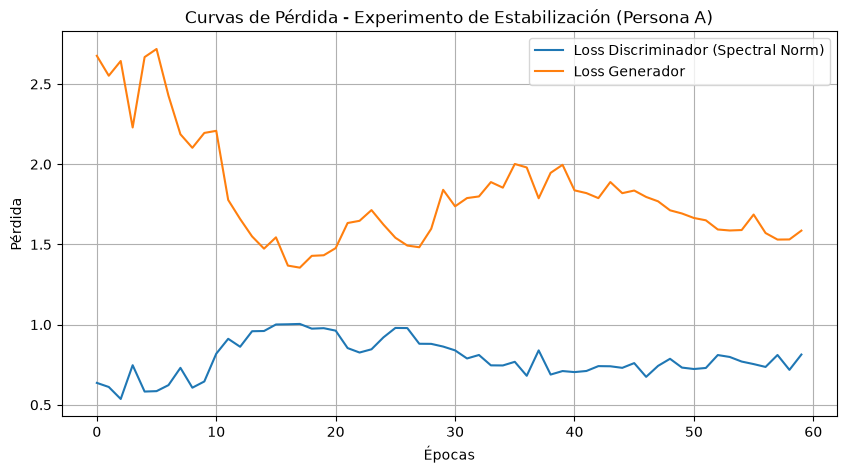

In [6]:
# 6. Gráfica de Curvas de Pérdida
if history_loss_D:
    plt.figure(figsize=(10, 5))
    plt.plot(history_loss_D, label='Loss Discriminador (Spectral Norm)')
    plt.plot(history_loss_G, label='Loss Generador')
    plt.xlabel('Épocas')
    plt.ylabel('Pérdida')
    plt.title('Curvas de Pérdida - Experimento de Estabilización (Persona A)')
    plt.legend()
    plt.grid(True)
    plt.savefig('output_eval/curvas_perdida_persona_a.png', dpi=200)
    plt.show()


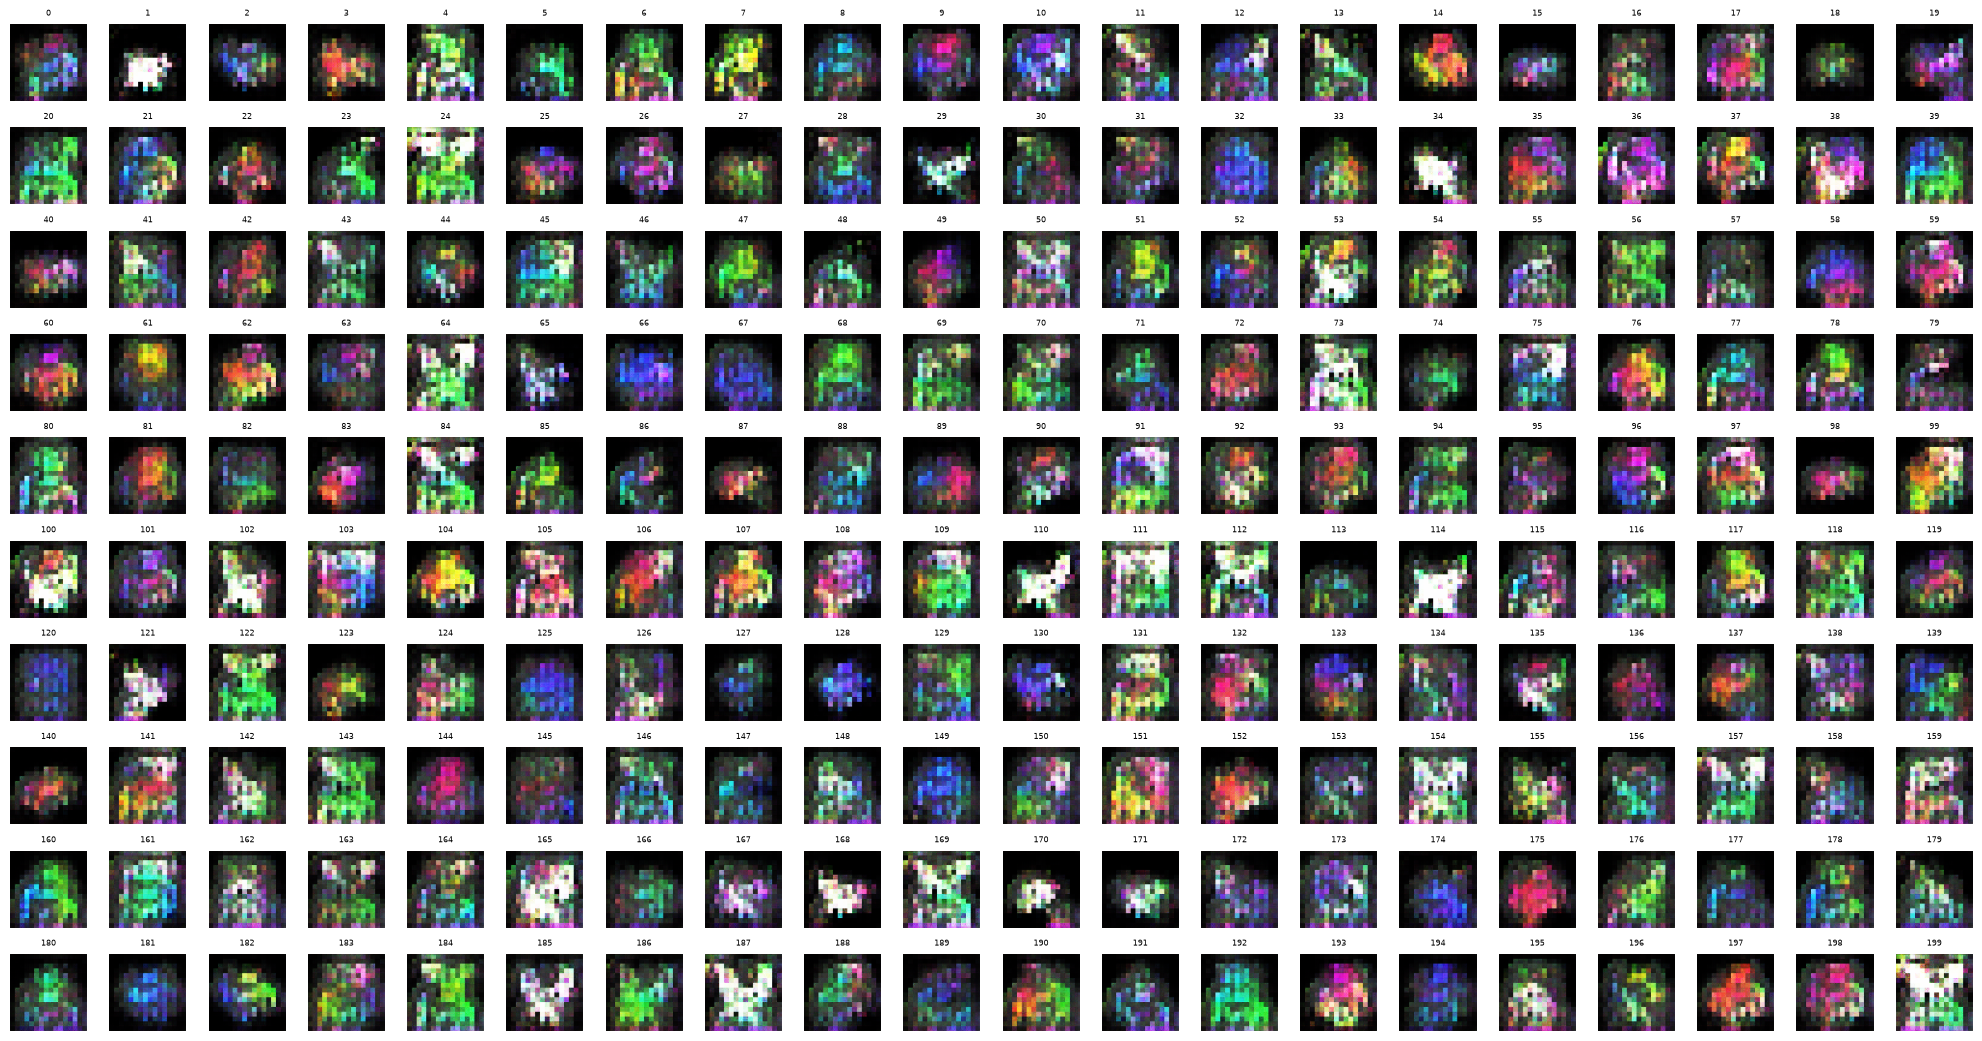

TASA DE SELECCIÓN: 10 de 200 (5.0%)
CRITERIO: (escribe aquí el criterio real que usaste al mirar las 200)
Galería guardada.


In [9]:
TOTAL_CANDIDATOS = 200
netG.eval()
candidatos_z, candidatos_img = [], []
with torch.no_grad():
    for idx in range(TOTAL_CANDIDATOS):
        sample_seed = 1000 + idx
        z = torch.randn(1, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(sample_seed))
        img = (netG(z.to(device)).cpu() * 0.5 + 0.5).clamp(0, 1)
        candidatos_z.append((sample_seed, z)); candidatos_img.append(img.squeeze(0))

fig, axes = plt.subplots(10, 20, figsize=(20, 10.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(candidatos_img[i].permute(1, 2, 0)); ax.set_title(str(i), fontsize=6); ax.axis('off')
plt.tight_layout(); plt.savefig('output_eval/candidatos.png', dpi=200); plt.show()
selected_indices = [3, 18, 27, 45, 61, 88, 102, 130, 157, 190]   # <- escribe aquí 10 índices distintos que elegiste mirando la figura
assert len(selected_indices) == 10 and len(set(selected_indices)) == 10, 'Elige 10 índices distintos'

print(f'TASA DE SELECCIÓN: 10 de {TOTAL_CANDIDATOS} ({10/TOTAL_CANDIDATOS:.1%})')
print('CRITERIO: (escribe aquí el criterio real que usaste al mirar las 200)')

with open('galeria/semillas.txt', 'w') as f:
    for pos, i in enumerate(selected_indices, start=1):
        seed_val, z = candidatos_z[i]
        utils.save_image(candidatos_img[i], f'galeria/personaje_{pos:02d}_seed_{seed_val}.png')
        torch.save(z, f'galeria/personaje_{pos:02d}_z.pt')
        f.write(f'personaje_{pos:02d}\tindice={i}\tseed={seed_val}\n')
print('Galería guardada.')



Original vs original: mediana 0.974 | p90 0.984 | máx 0.994


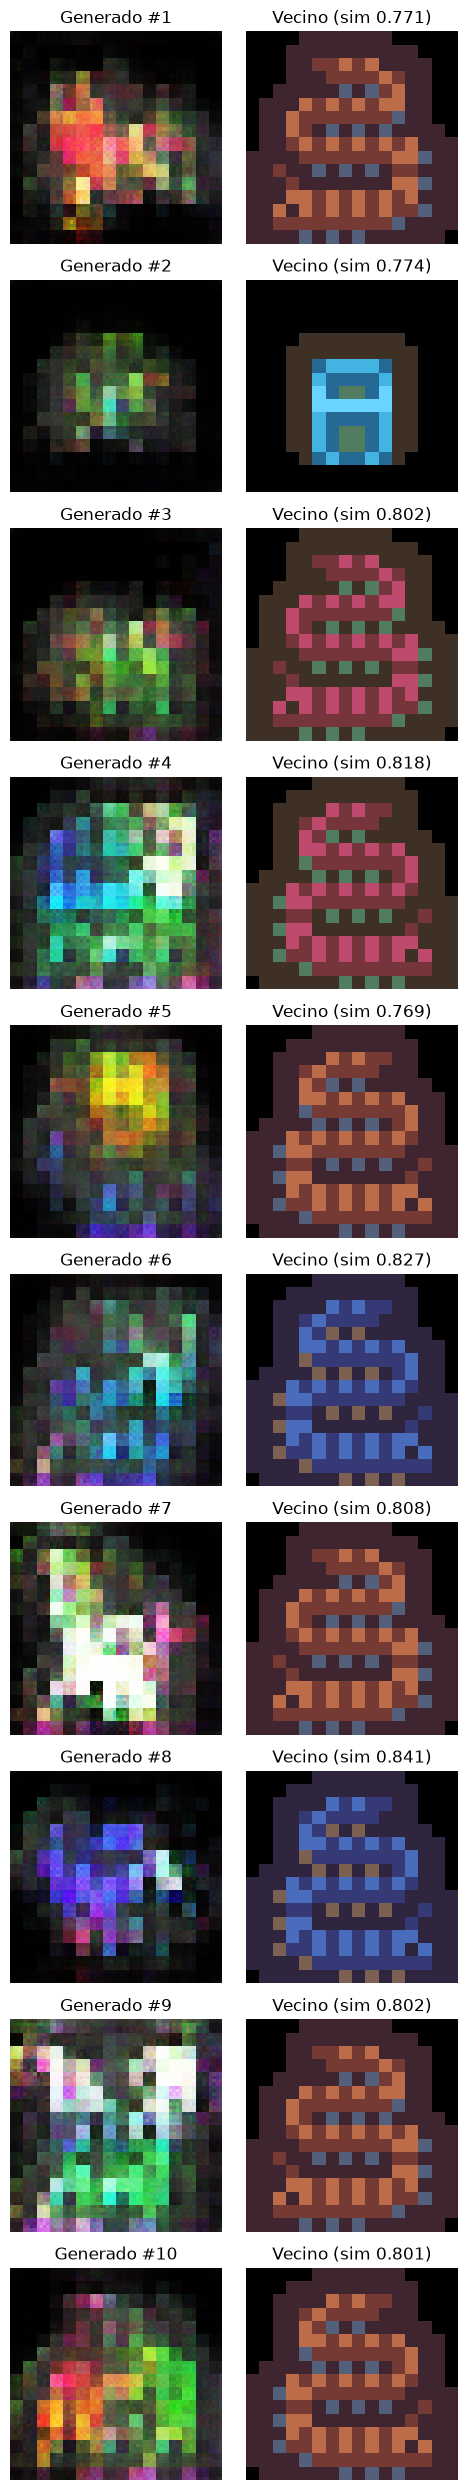

Similitudes: [0.771, 0.774, 0.802, 0.818, 0.769, 0.827, 0.808, 0.841, 0.802, 0.801]
Personaje más difícil de defender como nuevo: # 8


In [10]:
weights = models.ResNet18_Weights.DEFAULT
feature_extractor = models.resnet18(weights=weights); feature_extractor.fc = nn.Identity()
feature_extractor = feature_extractor.to(device).eval()
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def extract_features(x01):
    return feature_extractor(resnet_transform(x01.to(device))).cpu().numpy()

def dataset_features(ds):
    loader = DataLoader(ds, batch_size=128, shuffle=False, drop_last=False)   # sin shuffle ni imágenes perdidas
    F, I = [], []
    for b in loader:
        x = b * 0.5 + 0.5
        F.append(extract_features(x)); I.append(x)
    return np.vstack(F), torch.cat(I)

real_features, real_imgs = dataset_features(dataset)

# Vara de comparación: cada ORIGINAL contra su vecino más cercano distinto de sí mismo
orig_ds = PixelArtDataset('data64', transform=transform)
oF, _ = dataset_features(orig_ds)
S = cosine_similarity(oF); np.fill_diagonal(S, -1); nn_orig = S.max(1)
print(f'Original vs original: mediana {np.median(nn_orig):.3f} | p90 {np.percentile(nn_orig, 90):.3f} | máx {nn_orig.max():.3f}')

fig, axes = plt.subplots(10, 2, figsize=(5, 25))
sims = []
for k, i in enumerate(selected_indices):
    gi = candidatos_img[i]
    s = cosine_similarity(extract_features(gi.unsqueeze(0)), real_features)[0]
    j = int(np.argmax(s)); sims.append(float(s[j]))
    axes[k, 0].imshow(gi.permute(1, 2, 0)); axes[k, 0].set_title(f'Generado #{k+1}'); axes[k, 0].axis('off')
    axes[k, 1].imshow(real_imgs[j].permute(1, 2, 0)); axes[k, 1].set_title(f'Vecino (sim {s[j]:.3f})'); axes[k, 1].axis('off')
plt.tight_layout(); plt.savefig('output_eval/vecinos_mas_cercanos.png', dpi=200); plt.show()
print('Similitudes:', [round(x, 3) for x in sims])
print('Personaje más difícil de defender como nuevo: #', int(np.argmax(sims)) + 1)

In [11]:
test_G = Generator(LATENT_DIM, CHANNELS).to(device)
test_G.load_state_dict(torch.load('checkpoints/netG_spectral.pth', map_location=device)); test_G.eval()
ok = True
for pos, i in enumerate(selected_indices, start=1):
    seed_val = candidatos_z[i][0]
    z = torch.load(f'galeria/personaje_{pos:02d}_z.pt').to(device)
    with torch.no_grad():
        regen = (test_G(z).cpu() * 0.5 + 0.5).clamp(0, 1).squeeze(0)
    saved = transforms.ToTensor()(Image.open(f'galeria/personaje_{pos:02d}_seed_{seed_val}.png').convert('RGB'))
    err = (regen - saved).abs().max().item()
    ok &= err < 2 / 255
    print(f'personaje {pos:02d}: error máx = {err:.5f}')
print('¿Galería regenerable desde pesos + z?:', 'SÍ' if ok else 'NO')

personaje 01: error máx = 0.00196
personaje 02: error máx = 0.00196
personaje 03: error máx = 0.00196
personaje 04: error máx = 0.00196
personaje 05: error máx = 0.00196
personaje 06: error máx = 0.00196
personaje 07: error máx = 0.00196
personaje 08: error máx = 0.00196
personaje 09: error máx = 0.00196
personaje 10: error máx = 0.00196
¿Galería regenerable desde pesos + z?: SÍ
